
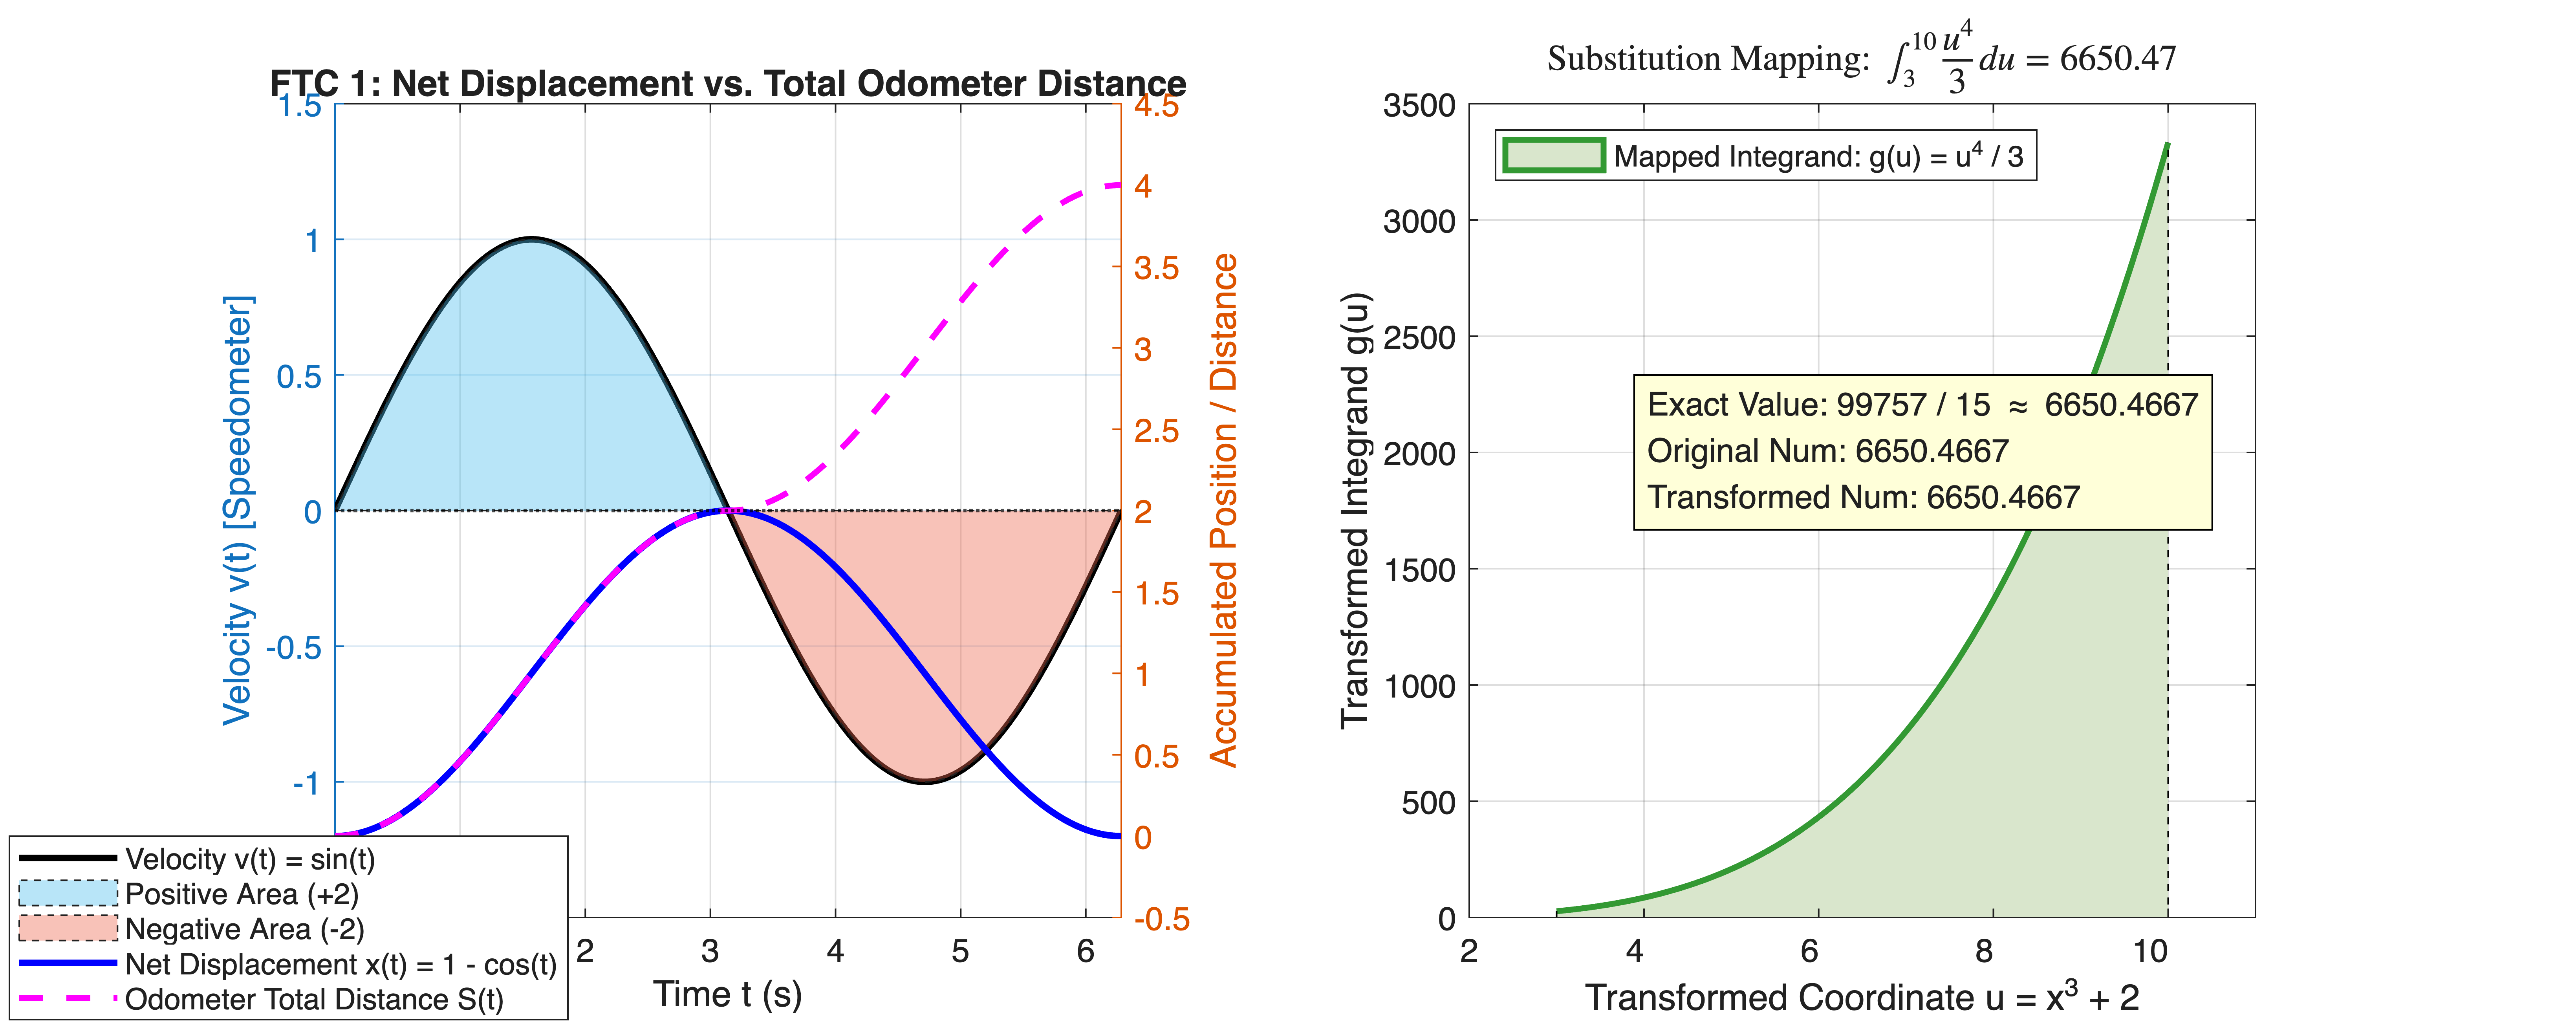

In [1]:
%% MIT 18.01 Lecture 19: Fundamental Theorem of Calculus & Definite Integrals
% Mathematical Tool Application: Solves state reconstruction from derivative inputs,
% contrasts net displacement with total odometer distance, and computes definite
% integrals via change-of-variable coordinate mapping.


clear; clc; close all;


%% Part 1: Kinematic FTC 1 Simulation: Speedometer vs. Odometer (v(t) = sin(t))
% Time horizon: 0 to 2*pi
t_span = linspace(0, 2*pi, 400);
v_signal = sin(t_span);


% FTC 1 Net Displacement: x(t) = \int_0^t v(\tau) d\tau = 1 - cos(t)
net_displacement = 1 - cos(t_span);


% Odometer Total Distance: S(t) = \int_0^t |v(\tau)| d\tau
% For [0, pi]: S(t) = 1 - cos(t); For [pi, 2*pi]: S(t) = 2 + (1 + cos(t)) = 3 + cos(t)
total_distance = zeros(size(t_span));
for k = 1:length(t_span)
    tk = t_span(k);
    total_distance(k) = integral(@(t) abs(sin(t)), 0, tk);
end


figure('Color', 'w', 'Position', [100, 100, 1200, 480]);


subplot(1, 2, 1);
yyaxis left;
plot(t_span, v_signal, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Velocity v(t) = sin(t)'); hold on;
yline(0, 'k:', 'LineWidth', 1.0, 'HandleVisibility', 'off');


% Fill positive and negative signed areas
t_half = linspace(0, pi, 200);
fill([t_half, pi, 0], [sin(t_half), 0, 0], [0.3, 0.75, 0.93], 'FaceAlpha', 0.4, ...
    'DisplayName', 'Positive Area (+2)');
t_second = linspace(pi, 2*pi, 200);
fill([t_second, 2*pi, pi], [sin(t_second), 0, 0], [0.93, 0.4, 0.3], 'FaceAlpha', 0.4, ...
    'DisplayName', 'Negative Area (-2)');
ylabel('Velocity v(t) [Speedometer]');
ylim([-1.5, 1.5]);


yyaxis right;
plot(t_span, net_displacement, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Net Displacement x(t) = 1 - cos(t)');
plot(t_span, total_distance, 'm--', 'LineWidth', 1.8, 'DisplayName', 'Odometer Total Distance S(t)');
ylabel('Accumulated Position / Distance');
ylim([-0.5, 4.5]);


grid on;
xlim([0, 2*pi]);
xlabel('Time t (s)');
title('FTC 1: Net Displacement vs. Total Odometer Distance');
legend('Location', 'northwest');


%% Part 2: Definite Integral by Substitution (Lecture 19 Example 7)
% Problem: \int_1^2 (x^3 + 2)^4 * x^2 dx  ==> Let u = x^3 + 2, du = 3*x^2 dx
% Transformed: \int_3^10 (1/3) * u^4 du
x1 = 1.0; x2 = 2.0;
u1 = x1^3 + 2.0; % u(1) = 3
u2 = x2^3 + 2.0; % u(2) = 10


% Exact Analytic Value: (10^5 - 3^5) / 15 = (100000 - 243) / 15 = 99757 / 15
exact_val = (10^5 - 3^5) / 15.0;


% Numerical integration on both forms
f_original = @(x) ((x.^3 + 2).^4) .* (x.^2);
g_substituted = @(u) (1.0 / 3.0) .* (u.^4);


int_orig_num = integral(f_original, x1, x2);
int_sub_num = integral(g_substituted, u1, u2);


subplot(1, 2, 2);
u_span = linspace(u1, u2, 300);
area(u_span, g_substituted(u_span), 'FaceColor', [0.85, 0.9, 0.8], 'EdgeColor', [0.2, 0.6, 0.2], ...
    'LineWidth', 1.8, 'DisplayName', 'Mapped Integrand: g(u) = u^4 / 3'); hold on;
plot([u1, u1], [0, g_substituted(u1)], 'k--', 'HandleVisibility', 'off');
plot([u2, u2], [0, g_substituted(u2)], 'k--', 'HandleVisibility', 'off');


grid on;
xlim([2, 11]);
xlabel('Transformed Coordinate u = x^3 + 2');
ylabel('Transformed Integrand g(u)');
title(sprintf('Substitution Mapping: $\\int_3^{10} \\frac{u^4}{3} du = %.2f$', exact_val), 'Interpreter', 'latex');
legend('Location', 'northwest');


text(4.0, 2000, sprintf('Exact Value: 99757 / 15 \\approx %.4f\nOriginal Num: %.4f\nTransformed Num: %.4f', ...
    exact_val, int_orig_num, int_sub_num), 'BackgroundColor', [1 1 0.85], 'EdgeColor', 'k');